<a href="https://colab.research.google.com/github/pakizahassan/Intro-to-CV/blob/main/Lab_8__Lab_Mid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images

**Name:** Pakiza Hassan  
**Reg Number:** FA23-BAI-034

## Personal Settings

| Setting | Rule | My value |
|---|---|---|
| Random seed | Last two digits of registration number `034` | **34** |
| HOG cell size | Last digit `4` is even | **8 × 8** |
| SIFT grid size | Last digit `4` is between 0 and 4 | **4 × 4 grid (16 keypoints)** |


## Q1. Data Setup (3 marks)


In [5]:
%pip install -q medmnist opencv-python scikit-image scikit-learn seaborn matplotlib pandas

 Import libraries and define personal settings

In [6]:
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

ROLL_NO = "034"
SEED = int(ROLL_NO[-2:])           # 34
HOG_CELL = (8, 8)                  # last digit 4 is even
SIFT_GRID = 4                      # last digit 4 is in the range 0–4
IMAGE_SIZE = (128, 128)
C_VALUES = [0.1, 1, 10]

CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = ["Eosinophil", "Monocyte", "Neutrophil", "Platelet"]

random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

print("Registration number:", ROLL_NO)
print("Random seed:", SEED)
print("HOG cell size:", HOG_CELL)
print("SIFT grid:", f"{SIFT_GRID} x {SIFT_GRID}")
print("Selected class IDs:", CLASS_IDS)

Registration number: 034
Random seed: 34
HOG cell size: (8, 8)
SIFT grid: 4 x 4
Selected class IDs: [1, 5, 6, 7]


 Load BloodMNIST



In [7]:
train_data = BloodMNIST(split="train", size=64, download=True)
val_data = BloodMNIST(split="val", size=64, download=True)
test_data = BloodMNIST(split="test", size=64, download=True)

X_train_all, y_train_all = train_data.imgs, train_data.labels.ravel()
X_val_all, y_val_all = val_data.imgs, val_data.labels.ravel()
X_test_all, y_test_all = test_data.imgs, test_data.labels.ravel()

print("Full train images:", X_train_all.shape, "labels:", y_train_all.shape)
print("Full validation images:", X_val_all.shape, "labels:", y_val_all.shape)
print("Full test images:", X_test_all.shape, "labels:", y_test_all.shape)

Full train images: (11959, 64, 64, 3) labels: (11959,)
Full validation images: (1712, 64, 64, 3) labels: (1712,)
Full test images: (3421, 64, 64, 3) labels: (3421,)


Select 100 training, 30 validation, and 30 test images per class


In [8]:
def select_samples(images, labels, n_per_class, seed):
    rng = np.random.default_rng(seed)
    chosen = []
    for class_id in CLASS_IDS:
        class_indices = np.flatnonzero(labels == class_id)
        if len(class_indices) < n_per_class:
            raise ValueError(f"Class {class_id} has only {len(class_indices)} images.")
        chosen.extend(rng.choice(class_indices, n_per_class, replace=False).tolist())
    chosen = np.array(chosen)
    rng.shuffle(chosen)
    return images[chosen], labels[chosen]

X_train, y_train = select_samples(X_train_all, y_train_all, 100, SEED)
X_val, y_val = select_samples(X_val_all, y_val_all, 30, SEED + 1)
X_test, y_test = select_samples(X_test_all, y_test_all, 30, SEED + 2)

for split_name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"\n{split_name} shape: X={X.shape}, y={y.shape}")
    for cid, cname in zip(CLASS_IDS, CLASS_NAMES):
        print(f"  {cname} ({cid}): {int(np.sum(y == cid))}")


Train shape: X=(400, 64, 64, 3), y=(400,)
  Eosinophil (1): 100
  Monocyte (5): 100
  Neutrophil (6): 100
  Platelet (7): 100

Validation shape: X=(120, 64, 64, 3), y=(120,)
  Eosinophil (1): 30
  Monocyte (5): 30
  Neutrophil (6): 30
  Platelet (7): 30

Test shape: X=(120, 64, 64, 3), y=(120,)
  Eosinophil (1): 30
  Monocyte (5): 30
  Neutrophil (6): 30
  Platelet (7): 30


In [9]:
counts = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Class ID": CLASS_IDS,
    "Train": [int(np.sum(y_train == c)) for c in CLASS_IDS],
    "Validation": [int(np.sum(y_val == c)) for c in CLASS_IDS],
    "Test": [int(np.sum(y_test == c)) for c in CLASS_IDS],
})
display(counts)

,Class,Class ID,Train,Validation,Test
0,Eosinophil,1,100,30,30
1,Monocyte,5,100,30,30
2,Neutrophil,6,100,30,30
3,Platelet,7,100,30,30


 Convert images to grayscale and resize to 128 × 128

BloodMNIST provides RGB images. HOG and the SIFT pipeline will use grayscale images.

In [10]:
def preprocess_image(image):
    if image.ndim == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image
    resized = cv2.resize(gray, IMAGE_SIZE, interpolation=cv2.INTER_LINEAR)
    return resized.astype(np.uint8)

X_train_gray = np.array([preprocess_image(im) for im in X_train])
X_val_gray = np.array([preprocess_image(im) for im in X_val])
X_test_gray = np.array([preprocess_image(im) for im in X_test])

print("Train grayscale:", X_train_gray.shape)
print("Validation grayscale:", X_val_gray.shape)
print("Test grayscale:", X_test_gray.shape)

Train grayscale: (400, 128, 128)
Validation grayscale: (120, 128, 128)
Test grayscale: (120, 128, 128)


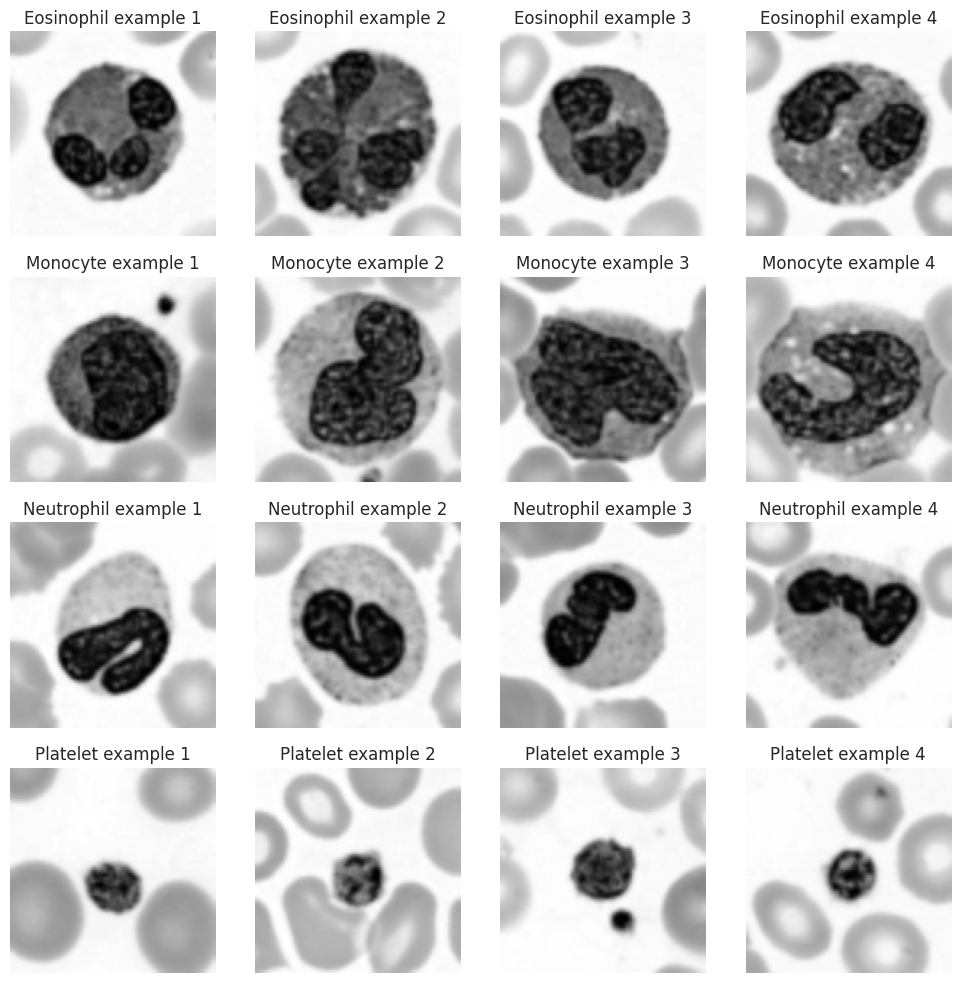

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for row, (cid, cname) in enumerate(zip(CLASS_IDS, CLASS_NAMES)):
    idx = np.flatnonzero(y_train == cid)[:4]
    for col, image_index in enumerate(idx):
        axes[row, col].imshow(X_train_gray[image_index], cmap="gray")
        axes[row, col].set_title(f"{cname} example {col + 1}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## Q2. HOG + SVM (6 marks)

HOG  describes local edge directions. HOG extracts features; SVM performs classification.



In [12]:
def extract_hog(image, visualize=False):
    return hog(
        image,
        orientations=9,
        pixels_per_cell=HOG_CELL,
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=visualize,
        feature_vector=True
    )

X_train_hog = np.array([extract_hog(im) for im in X_train_gray])
X_val_hog = np.array([extract_hog(im) for im in X_val_gray])

print("HOG training feature matrix:", X_train_hog.shape)
print("HOG validation feature matrix:", X_val_hog.shape)
print("HOG feature length:", X_train_hog.shape[1])

HOG training feature matrix: (400, 8100)
HOG validation feature matrix: (120, 8100)
HOG feature length: 8100


### Q2.1 — HOG feature-length calculation

For a 128 × 128 image with an 8 × 8 cell size, there are 128/8 = 16 cells along each dimension. With 2 × 2 cells per block, there are (16 − 2 + 1) = 15 block positions in each dimension. Each block contains 2 × 2 × 9 = 36 values. Therefore, the feature length is 15 × 15 × 36 = **8100 features**.

 HOG visualization for one image per class

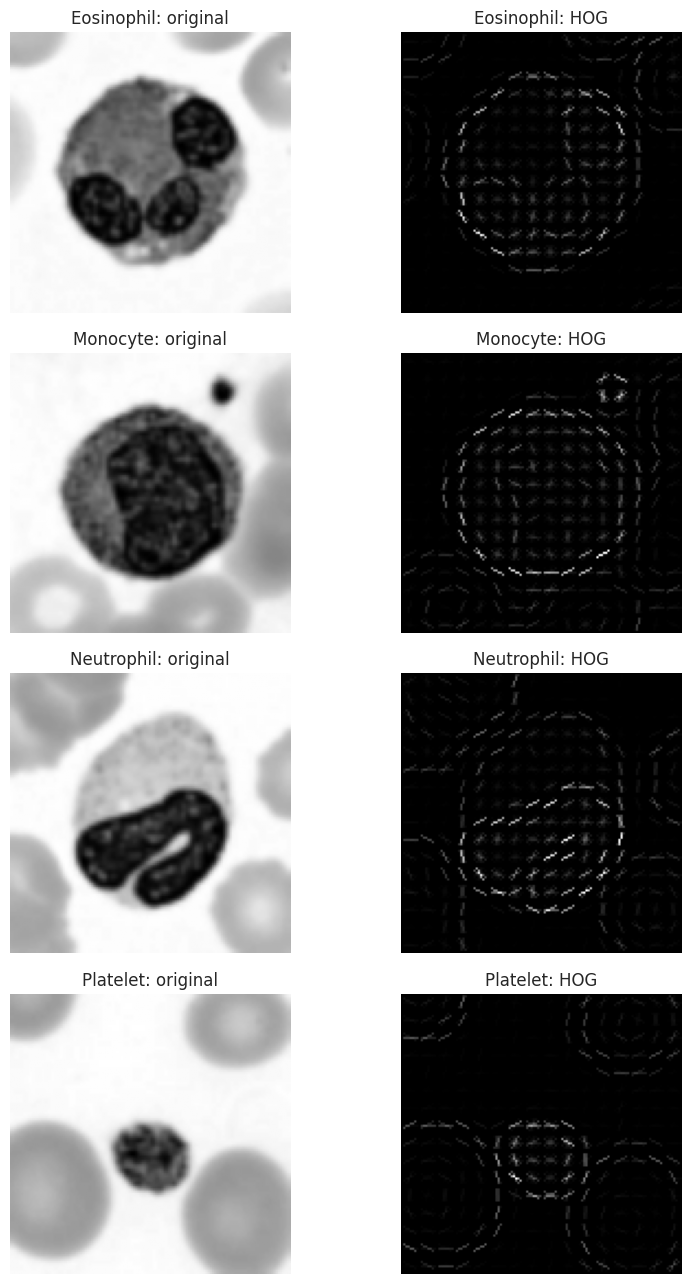

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(9, 13))
for row, (cid, cname) in enumerate(zip(CLASS_IDS, CLASS_NAMES)):
    image_index = np.flatnonzero(y_train == cid)[0]
    _, hog_image = extract_hog(X_train_gray[image_index], visualize=True)
    axes[row, 0].imshow(X_train_gray[image_index], cmap="gray")
    axes[row, 0].set_title(f"{cname}: original")
    axes[row, 1].imshow(hog_image, cmap="gray")
    axes[row, 1].set_title(f"{cname}: HOG")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")
plt.tight_layout()
plt.show()

In [14]:
print("HOG training shape:", X_train_hog.shape)
print("HOG validation shape:", X_val_hog.shape)

HOG training shape: (400, 8100)
HOG validation shape: (120, 8100)


 Train HOG + SVM and choose C using validation data


In [16]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

C_VALUES = [0.1, 1, 10]

def train_and_select_c(Xtr, ytr, Xv, yv, model_name):
    print("Scaling features...", flush=True)

    scaler = StandardScaler()
    Xtr_scaled = scaler.fit_transform(Xtr)
    Xv_scaled = scaler.transform(Xv)

    rows = []
    best_accuracy = -1
    best_model, best_c = None, None

    for c_value in C_VALUES:
        print(f"Training {model_name} with C={c_value}...", flush=True)

        model = LinearSVC(
            C=c_value,
            random_state=SEED,
            max_iter=3000,
            tol=1e-2,
            dual=True
        )

        model.fit(Xtr_scaled, ytr)
        val_pred = model.predict(Xv_scaled)

        val_accuracy = accuracy_score(yv, val_pred)
        val_macro_f1 = f1_score(
            yv, val_pred,
            labels=CLASS_IDS,
            average="macro",
            zero_division=0
        )

        rows.append({
            "Model": model_name,
            "C": c_value,
            "Validation accuracy": val_accuracy,
            "Validation macro-F1": val_macro_f1
        })

        print(
            f"Accuracy: {val_accuracy:.4f} | "
            f"Macro-F1: {val_macro_f1:.4f}",
            flush=True
        )

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_model, best_c = model, c_value

    display(pd.DataFrame(rows))
    print(f"{model_name}: selected C = {best_c}")

    return best_model, scaler, best_c

In [17]:
hog_model, hog_scaler, hog_c = train_and_select_c(
    X_train_hog,
    y_train,
    X_val_hog,
    y_val,
    "HOG + SVM"
)

Scaling features...
Training HOG + SVM with C=0.1...
Accuracy: 0.6917 | Macro-F1: 0.6882
Training HOG + SVM with C=1...
Accuracy: 0.6917 | Macro-F1: 0.6882
Training HOG + SVM with C=10...
Accuracy: 0.6917 | Macro-F1: 0.6882


,Model,C,Validation accuracy,Validation macro-F1
0,HOG + SVM,0.1,0.691667,0.688173
1,HOG + SVM,1.0,0.691667,0.688173
2,HOG + SVM,10.0,0.691667,0.688173


HOG + SVM: selected C = 0.1


HOG + SVM validation accuracy: 0.6917 (69.17%)
HOG + SVM validation macro-F1: 0.6882 (68.82%)

Classification report:
              precision    recall  f1-score   support

  Eosinophil       0.58      0.47      0.52        30
    Monocyte       0.56      0.73      0.64        30
  Neutrophil       0.63      0.57      0.60        30
    Platelet       1.00      1.00      1.00        30

    accuracy                           0.69       120
   macro avg       0.69      0.69      0.69       120
weighted avg       0.69      0.69      0.69       120



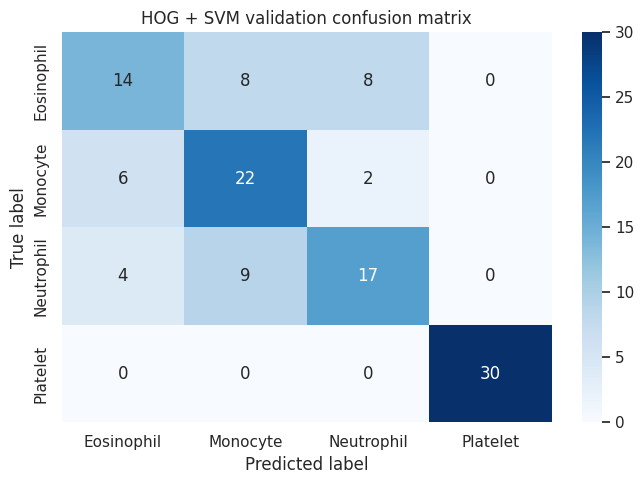

In [18]:
def show_validation_results(model, scaler, features, labels, title):
    predictions = model.predict(scaler.transform(features))
    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(
        labels, predictions, labels=CLASS_IDS, average="macro", zero_division=0
    )
    cm = confusion_matrix(labels, predictions, labels=CLASS_IDS)

    print(f"{title} validation accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"{title} validation macro-F1: {macro_f1:.4f} ({macro_f1*100:.2f}%)")
    print("\nClassification report:")
    print(classification_report(
        labels, predictions, labels=CLASS_IDS,
        target_names=CLASS_NAMES, zero_division=0
    ))

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
    )
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"{title} validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return predictions, cm, accuracy, macro_f1

hog_val_pred, hog_val_cm, hog_val_acc, hog_val_f1 = show_validation_results(
    hog_model, hog_scaler, X_val_hog, y_val, "HOG + SVM"
)

## Q3. SIFT + SVM (7 marks)



In [19]:
sift = cv2.SIFT_create()
natural_keypoint_counts = []

for image in X_train_gray:
    keypoints, descriptors = sift.detectAndCompute(image, None)
    natural_keypoint_counts.append(len(keypoints))

natural_keypoint_counts = np.array(natural_keypoint_counts)
print("Average keypoints per image:", round(float(natural_keypoint_counts.mean()), 2))
print("Minimum keypoints:", int(natural_keypoint_counts.min()))
print("Maximum keypoints:", int(natural_keypoint_counts.max()))
print("Images with zero keypoints:", int(np.sum(natural_keypoint_counts == 0)))

Average keypoints per image: 72.3
Minimum keypoints: 9
Maximum keypoints: 178
Images with zero keypoints: 0


 natural SIFT keypoints on one image

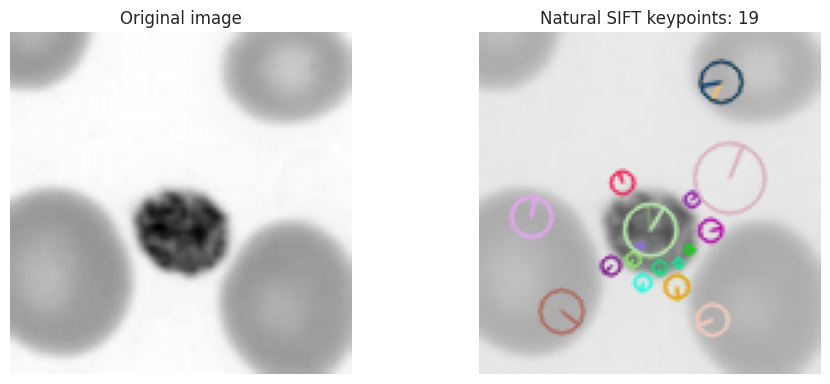

In [20]:
example_image = X_train_gray[0]
keypoints, descriptors = sift.detectAndCompute(example_image, None)
keypoint_image = cv2.drawKeypoints(
    example_image, keypoints, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(example_image, cmap="gray")
axes[0].set_title("Original image")
axes[1].imshow(keypoint_image, cmap="gray")
axes[1].set_title(f"Natural SIFT keypoints: {len(keypoints)}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Q3 explanation:** Natural SIFT produces a different number of keypoints for different images, but a standard SVM expects every input feature vector to have the same length.

 Create a fixed grid of SIFT keypoints and extract descriptors

The grid has 4 × 4 = 16 keypoints. Each descriptor has 128 values, so each image has 16 × 128 = **2048 features**. Keypoint size is 32.

In [21]:
def make_grid_keypoints(image, grid_size=SIFT_GRID):
    height, width = image.shape
    keypoints = []
    for row in range(grid_size):
        for col in range(grid_size):
            x = (col + 0.5) * width / grid_size
            y = (row + 0.5) * height / grid_size
            keypoints.append(cv2.KeyPoint(float(x), float(y), 32))
    return keypoints

def extract_grid_sift(image):
    keypoints = make_grid_keypoints(image)
    computed_keypoints, descriptors = sift.compute(image, keypoints)
    expected_shape = (SIFT_GRID * SIFT_GRID, 128)
    if descriptors is None or descriptors.shape != expected_shape:
        actual_shape = None if descriptors is None else descriptors.shape
        raise ValueError(
            f"SIFT expected descriptor shape {expected_shape}, got {actual_shape}"
        )
    return descriptors.flatten()

X_train_sift = np.array([extract_grid_sift(im) for im in X_train_gray])
X_val_sift = np.array([extract_grid_sift(im) for im in X_val_gray])

print("SIFT training feature matrix:", X_train_sift.shape)
print("SIFT validation feature matrix:", X_val_sift.shape)
print("SIFT feature length:", X_train_sift.shape[1])

SIFT training feature matrix: (400, 2048)
SIFT validation feature matrix: (120, 2048)
SIFT feature length: 2048


### Q3.2 — SIFT feature-length calculation

My SIFT grid is 4 × 4, so it contains 4 × 4 = 16 keypoints. Each SIFT descriptor contains 128 values. The final feature length is 16 × 128 = **2048 features**.

 Visualize the fixed 4 × 4 grid

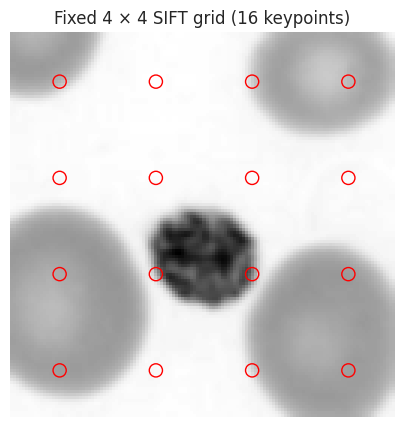

In [22]:
grid_example = X_train_gray[0]
grid_points = make_grid_keypoints(grid_example)

plt.figure(figsize=(5, 5))
plt.imshow(grid_example, cmap="gray")
plt.scatter(
    [point.pt[0] for point in grid_points],
    [point.pt[1] for point in grid_points],
    s=90, facecolors="none", edgecolors="red"
)
plt.title("Fixed 4 × 4 SIFT grid (16 keypoints)")
plt.axis("off")
plt.show()

Train SIFT + SVM and choose C using validation data

In [23]:
sift_model, sift_scaler, sift_c = train_and_select_c(
    X_train_sift, y_train, X_val_sift, y_val, "SIFT + SVM"
)

Scaling features...
Training SIFT + SVM with C=0.1...
Accuracy: 0.7250 | Macro-F1: 0.7234
Training SIFT + SVM with C=1...
Accuracy: 0.7333 | Macro-F1: 0.7345
Training SIFT + SVM with C=10...
Accuracy: 0.7333 | Macro-F1: 0.7345


,Model,C,Validation accuracy,Validation macro-F1
0,SIFT + SVM,0.1,0.725000,0.723430
1,SIFT + SVM,1.0,0.733333,0.734535
2,SIFT + SVM,10.0,0.733333,0.734535


SIFT + SVM: selected C = 1


SIFT + SVM validation accuracy: 0.7333 (73.33%)
SIFT + SVM validation macro-F1: 0.7345 (73.45%)

Classification report:
              precision    recall  f1-score   support

  Eosinophil       0.64      0.53      0.58        30
    Monocyte       0.59      0.77      0.67        30
  Neutrophil       0.75      0.70      0.72        30
    Platelet       1.00      0.93      0.97        30

    accuracy                           0.73       120
   macro avg       0.74      0.73      0.73       120
weighted avg       0.74      0.73      0.73       120



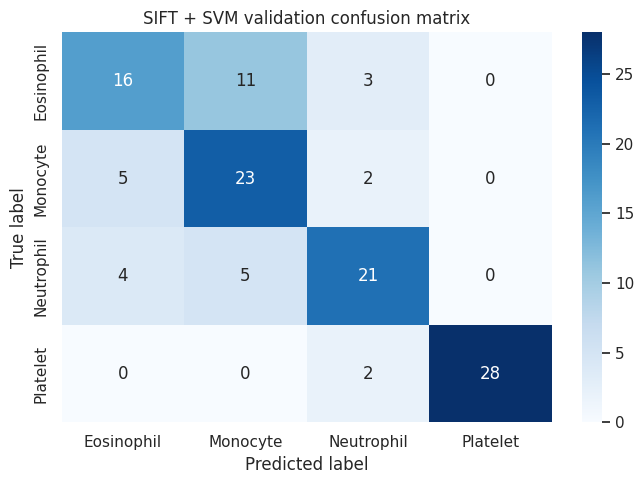

In [24]:
sift_val_pred, sift_val_cm, sift_val_acc, sift_val_f1 = show_validation_results(
    sift_model, sift_scaler, X_val_sift, y_val, "SIFT + SVM"
)

In [25]:
validation_comparison = pd.DataFrame({
    "Model": ["HOG + SVM", "SIFT + SVM"],
    "Chosen C": [hog_c, sift_c],
    "Validation accuracy": [hog_val_acc, sift_val_acc],
    "Validation macro-F1": [hog_val_f1, sift_val_f1],
    "Feature length": [X_train_hog.shape[1], X_train_sift.shape[1]]
})
display(validation_comparison)

,Model,Chosen C,Validation accuracy,Validation macro-F1,Feature length
0,HOG + SVM,0.1,0.691667,0.688173,8100
1,SIFT + SVM,1.0,0.733333,0.734535,2048


## Q4. Robustness (6 marks)

### Q4.1 Prediction

**Rotation prediction:** I predict that HOG may lose more accuracy under rotation because rotating an image changes the gradient directions summarized by HOG.

**Noise prediction:** I predict that HOG may lose more accuracy under noise because noise can add unwanted gradients to the image.

These are predictions, not results. Compare them with the output table after the test.

Create rotated and noisy versions of the test images

The test images are transformed **before feature extraction**. Rotation is 20 degrees. For noise, pixels are scaled to 0–1 and Gaussian noise with sigma = 0.05 is added.

In [26]:
def rotate_image_20_degrees(image):
    height, width = image.shape
    matrix = cv2.getRotationMatrix2D((width / 2, height / 2), 20, 1.0)
    return cv2.warpAffine(
        image, matrix, (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

def add_gaussian_noise(image, rng, sigma=0.05):
    image_01 = image.astype(np.float32) / 255.0
    noise = rng.normal(loc=0.0, scale=sigma, size=image_01.shape)
    noisy_01 = np.clip(image_01 + noise, 0.0, 1.0)
    return np.rint(noisy_01 * 255).astype(np.uint8)

noise_rng = np.random.default_rng(SEED)
X_test_rotated = np.array([rotate_image_20_degrees(im) for im in X_test_gray])
X_test_noisy = np.array([
    add_gaussian_noise(im, noise_rng, sigma=0.05) for im in X_test_gray
])

print("Clean test images:", X_test_gray.shape)
print("Rotated test images:", X_test_rotated.shape)
print("Noisy test images:", X_test_noisy.shape)

Clean test images: (120, 128, 128)
Rotated test images: (120, 128, 128)
Noisy test images: (120, 128, 128)


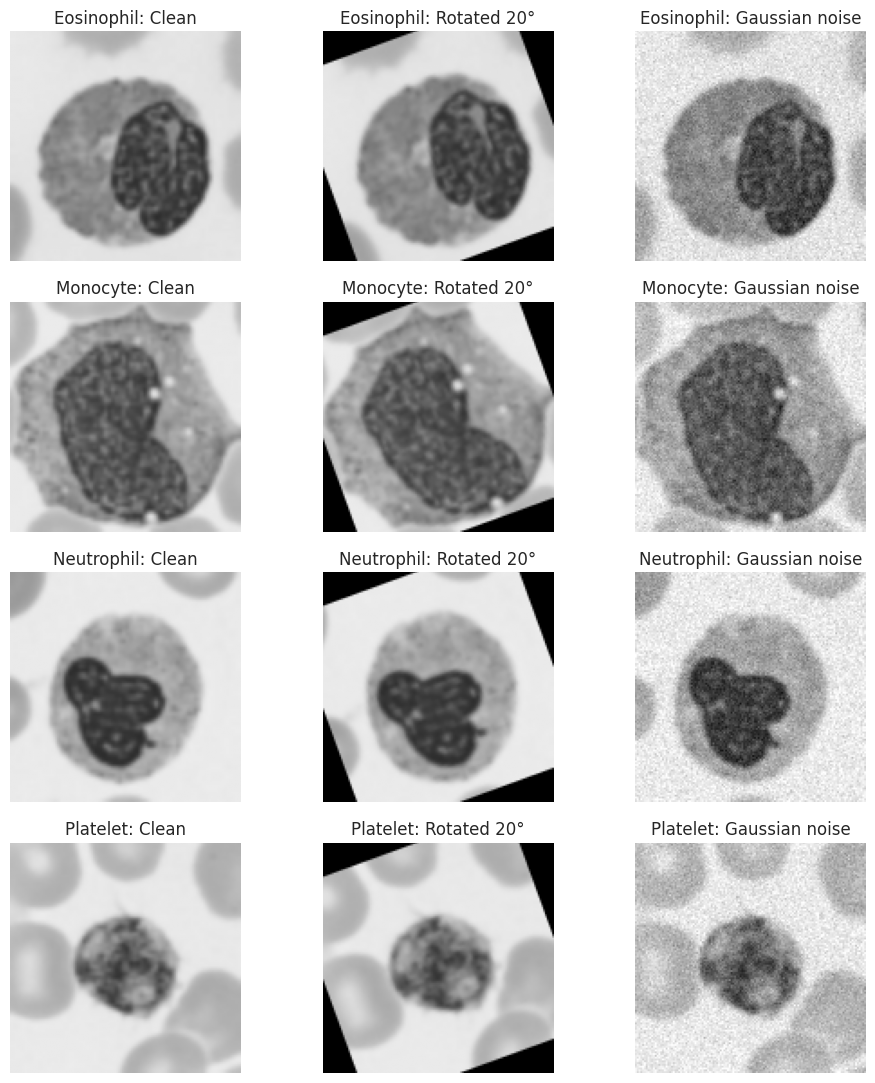

In [27]:
fig, axes = plt.subplots(4, 3, figsize=(10, 11))
for row, (class_id, class_name) in enumerate(zip(CLASS_IDS, CLASS_NAMES)):
    image_index = np.flatnonzero(y_test == class_id)[0]
    examples = [
        ("Clean", X_test_gray[image_index]),
        ("Rotated 20°", X_test_rotated[image_index]),
        ("Gaussian noise", X_test_noisy[image_index])
    ]
    for col, (title, image) in enumerate(examples):
        axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{class_name}: {title}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [28]:
def evaluate_test_condition(model, scaler, images, labels, feature_function):
    features = np.array([feature_function(image) for image in images])
    scaled_features = scaler.transform(features)
    predictions = model.predict(scaled_features)
    return accuracy_score(labels, predictions)

robustness_rows = []
for model_name, model, scaler, feature_function in [
    ("HOG + SVM", hog_model, hog_scaler, extract_hog),
    ("SIFT + SVM", sift_model, sift_scaler, extract_grid_sift)
]:
    clean_acc = evaluate_test_condition(
        model, scaler, X_test_gray, y_test, feature_function
    )
    rotated_acc = evaluate_test_condition(
        model, scaler, X_test_rotated, y_test, feature_function
    )
    noisy_acc = evaluate_test_condition(
        model, scaler, X_test_noisy, y_test, feature_function
    )
    robustness_rows.append({
        "Model": model_name,
        "Clean accuracy": clean_acc,
        "Rotated accuracy": rotated_acc,
        "Noisy accuracy": noisy_acc
    })

robustness_results = pd.DataFrame(robustness_rows)
display(
    robustness_results.style.format({
        "Clean accuracy": "{:.2%}",
        "Rotated accuracy": "{:.2%}",
        "Noisy accuracy": "{:.2%}"
    })
)

,Model,Clean accuracy,Rotated accuracy,Noisy accuracy
0,HOG + SVM,71.67%,63.33%,25.00%
1,SIFT + SVM,75.83%,31.67%,70.83%


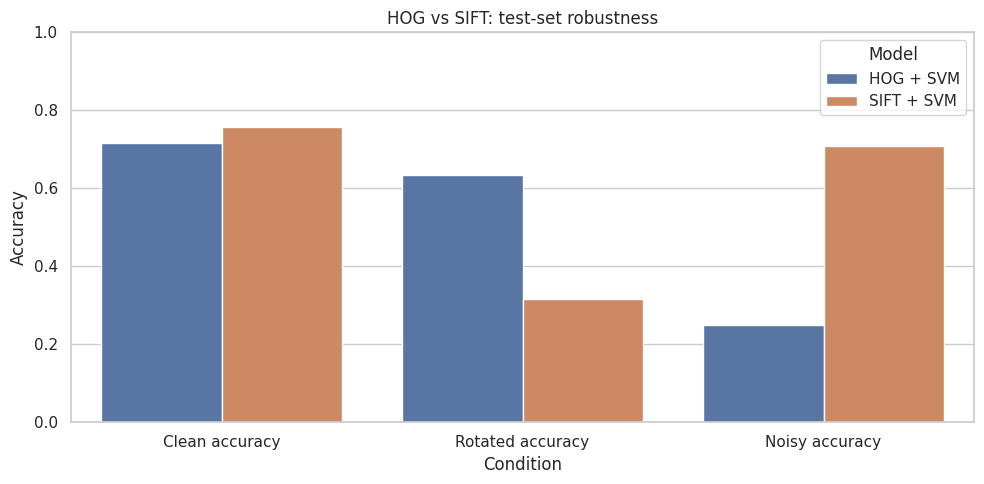

,Model,Rotation accuracy drop,Noise accuracy drop
0,HOG + SVM,8.33%,46.67%
1,SIFT + SVM,44.17%,5.00%


In [29]:
robustness_plot = robustness_results.melt(
    id_vars="Model", var_name="Condition", value_name="Accuracy"
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=robustness_plot, x="Condition", y="Accuracy", hue="Model"
)
ax.set_ylim(0, 1)
ax.set_title("HOG vs SIFT: test-set robustness")
ax.set_ylabel("Accuracy")
plt.tight_layout()
plt.show()

drop_table = robustness_results[["Model"]].copy()
drop_table["Rotation accuracy drop"] = (
    robustness_results["Clean accuracy"] - robustness_results["Rotated accuracy"]
)
drop_table["Noise accuracy drop"] = (
    robustness_results["Clean accuracy"] - robustness_results["Noisy accuracy"]
)
display(drop_table.style.format({
    "Rotation accuracy drop": "{:.2%}",
    "Noise accuracy drop": "{:.2%}"
}))

### Q4.2 — Results table



| Model | Clean accuracy | Rotated accuracy | Noisy accuracy |
|---|---:|---:|---:|
| HOG + SVM |   71.67%   |    63.33%    | 25.00%           |
| SIFT + SVM|   75.83%	 |    31.67%	  | 70.83%           |

### Q4.3 — Was your prediction correct?

1. Under rotation, **SIFT + SVM** lost more accuracy because its accuracy changed from **75.83%** to **31.67%**, a decrease of **44.16 percentage points**.

2. Under noise, **HOG + SVM** lost more accuracy because its accuracy changed from **71.67%** to **25.00%**, a decrease of **46.67 percentage points**.

3. Therefore, my prediction was **[correct / partly correct / incorrect]** based on the measured results.



## Q5. Short Answers and AI Log (3 marks)



In [30]:
combined_validation_cm = hog_val_cm + sift_val_cm
pair_rows = []

for i in range(len(CLASS_IDS)):
    for j in range(i + 1, len(CLASS_IDS)):
        pair_rows.append({
            "Class 1": CLASS_NAMES[i],
            "Class 2": CLASS_NAMES[j],
            "Combined cross-confusion": int(
                combined_validation_cm[i, j] + combined_validation_cm[j, i]
            )
        })

confused_pairs = pd.DataFrame(pair_rows).sort_values(
    "Combined cross-confusion", ascending=False
).reset_index(drop=True)
display(confused_pairs)
print("Most-confused pair based on combined validation matrices:")
print(confused_pairs.iloc[0].to_dict())

,Class 1,Class 2,Combined cross-confusion
0,Eosinophil,Monocyte,30
1,Eosinophil,Neutrophil,19
2,Monocyte,Neutrophil,18
3,Neutrophil,Platelet,2
4,Eosinophil,Platelet,0
5,Monocyte,Platelet,0


Most-confused pair based on combined validation matrices:
{'Class 1': 'Eosinophil', 'Class 2': 'Monocyte', 'Combined cross-confusion': 30}


### Q5.1 (a) Why does HOG use block normalisation?
HOG uses block normalisation to reduce the effects of lighting and contrast changes. It makes gradient features more consistent across image regions and can improve classification accuracy.

### Q5.1 (b) Why is it wrong to choose C using the test set?
The test set should be reserved for the final evaluation of the model on unseen data. Choosing C using test-set performance leaks information from the test set and may lead to an overly optimistic evaluation. Therefore, C should be selected using the validation set.

### Q5.2 Which two classes did your models confuse most, and why might grayscale make this harder?
The two classes confused most were **Eosinophil and Monocyte**, with a combined cross-confusion count of **30** according to the validation confusion matrices. These classes may have similar visual features, making them difficult for the models to distinguish. Grayscale removes colour information, including staining differences, so the models must rely mainly on shape, texture, and gradient features to classify the cells.

### Cell 24 — AI usage log

This is a template. Edit it so it accurately reflects the AI prompts you actually used, what you changed, and how you checked each result.

In [31]:
ai_log = pd.DataFrame([
    {
        "Prompt (one line)": "Help me organize a HOG and SIFT BloodMNIST classification notebook.",
        "What I changed": "Set registration-specific seed, HOG cell size, and SIFT grid size.",
        "How I checked": "Printed the settings, data shapes, and class counts."
    },
    {
        "Prompt (one line)": "Explain how to extract fixed-length SIFT features and train an SVM.",
        "What I changed": "Used a fixed 4 x 4 keypoint grid and validation-based C selection.",
        "How I checked": "Printed feature matrix shapes and feature length; checked validation metrics."
    },
    {
        "Prompt (one line)": "Help test HOG and SIFT under image rotation and Gaussian noise.",
        "What I changed": "Applied 20-degree rotation and Gaussian noise before feature extraction.",
        "How I checked": "Viewed transformed images and compared test accuracies in the output table."
    }
])
display(ai_log)

,Prompt (one line),What I changed,How I checked
0,Help me organize a HOG and SIFT BloodMNIST cla...,"Set registration-specific seed, HOG cell size,...","Printed the settings, data shapes, and class c..."
1,Explain how to extract fixed-length SIFT featu...,Used a fixed 4 x 4 keypoint grid and validatio...,Printed feature matrix shapes and feature leng...
2,Help test HOG and SIFT under image rotation an...,Applied 20-degree rotation and Gaussian noise ...,Viewed transformed images and compared test ac...
